# Batches and Jacobians you already use

`vmap`, `jacfwd`, `jacrev` and `hessian` work on a hawk kernel as they do on any JAX function. Some of them cost
one launch, some one per batch entry. This page shows which, then draws a loss surface with them.

**Time:** ~5 min · **Runs on:** CPU, GPU if visible (picked up automatically) · **You need:** eagle, hawk and JAX

You will build: the launch count of each transformation, a Jacobian two ways, and a map of a two-Param loss with its
gradient arrows and curvature.

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [ ]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    from packaging.version import Version

    try:
        old = Version(importlib.metadata.version("jax")) < Version("0.11.2")
    except importlib.metadata.PackageNotFoundError:
        old = True
    if old:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"jax{extra}>=0.11.2"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import plot_style
plot_style()

## The kernel

The same drag step as the training tutorial, with `g` a `Param` too, so there are two numbers to vary.

In [3]:
import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")  # leave GPU memory for your other libraries
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)  # the kernel runs in float64

import hawk
from hawk import Mutable, Param, Vector
from hawk.math import norm, vec

from eagle.frameworks import jax as eagle_jax


@hawk.kernel
def drag_step(v: Vector[3], cd: Param, dt: Param, g: Param, v_next: Mutable[Vector[3]]):
    a = vec(0.0, 0.0, -g) - cd * norm(v) * v
    v_next = v + dt * a

step = eagle_jax.function(drag_step, wrt=("v", "cd", "g"))

## `vmap` over trajectories: one launch

Eight batches of 256 balls. `vmap` folds the batch into the kernel's sample axis, so the whole thing is one
launch. It is free for `in_axes=-1`; a leading batch axis costs one transpose.

In [4]:
batches = jax.random.normal(jax.random.key(0), (8, 3, 256))
over_axis0 = jax.vmap(lambda v: step(v, 0.05, 0.02, 9.81))
looped = jnp.stack([step(v, 0.05, 0.02, 9.81) for v in batches])
assert jnp.allclose(over_axis0(batches), looped)
print("vmap over 8 batches:", over_axis0(batches).shape, "| same as 8 separate calls")

vmap over 8 batches: (8, 3, 256) | same as 8 separate calls


## `vmap` over Params: one launch too

A batch of `Param` values is not a sample axis, so the kernel reads its own value from a table, one entry per
batch entry: one launch over all the samples of all the entries. Count the launches by reading the lowered
program: the call sites, and whether they sit in a loop.

In [5]:
v = batches[0]
cds = jnp.linspace(0.01, 0.2, 8)
cases = {
    "one call":               (lambda v: step(v, 0.05, 0.02, 9.81), (v,)),
    "vmap over planes":       (over_axis0, (batches,)),
    "vmap over Params":       (jax.vmap(lambda c: step(v, c, 0.02, 9.81)), (cds,)),
    "grad":                   (jax.grad(lambda c: step(v, c, 0.02, 9.81).sum()), (0.05,)),
    "jacrev over the planes": (jax.jacrev(lambda x: step(x, 0.05, 0.02, 9.81)), (v[:, :4],)),
    "jacfwd over the planes": (jax.jacfwd(lambda x: step(x, 0.05, 0.02, 9.81)), (v[:, :4],)),
}
print(f"{'':<24}{'launch sites':<14}launches")
for name, (f, args) in cases.items():
    text = jax.jit(f).lower(*args).as_text()
    in_loop = "stablehlo.while" in text
    print(f"{name:<24}{text.count('eagle_xla_launch'):<14}{'one per entry (loop)' if in_loop else 'one'}")

                        launch sites  launches
one call                1             one
vmap over planes        1             one
vmap over Params        1             one
grad                    1             one
jacrev over the planes  1             one
jacfwd over the planes  1             one


## Jacobians, two ways

How does one ball's final velocity depend on its launch velocity? `jacfwd` and `jacrev` give the same 3 x 3
matrix, from the forward and the reverse kernel hawk derived.

In [6]:
def final_velocity(v_launch):
    v = jnp.tile(v_launch[:, None], (1, 4))  # four copies: a kernel wants a batch
    for _ in range(20):
        v = step(v, 0.05, 0.02, 9.81)
    return v[:, 0]


v_launch = jnp.array([6.0, 2.0, 8.0])
J_fwd, J_rev = jax.jacfwd(final_velocity)(v_launch), jax.jacrev(final_velocity)(v_launch)
assert jnp.allclose(J_fwd, J_rev)
print("d final velocity / d launch velocity:")
print(jnp.round(J_fwd, 4))

d final velocity / d launch velocity:
[[ 0.7894 -0.0201 -0.0591]
 [-0.0201  0.843  -0.0197]
 [-0.0603 -0.0201  0.7878]]


## Forward mode through a stepping kernel

A kernel that carries state and a stop mask differentiates in forward mode too. Here a ball falls with drag until
it lands; `jvp` and `jacfwd` through twenty steps agree with `jacrev` and with finite differences. A ball that
landed early took fewer steps, so its derivative with respect to `cd` is smaller.

In [7]:
from hawk import Scalar, Terminated


@hawk.kernel(steps=1)
def fall(h: Scalar, v: Scalar, cd: Param, dt: Param, terminated: Terminated,
         h_next: Mutable[Scalar], v_next: Mutable[Scalar]):
    v_next = v + dt * (cd * v * v - 9.81)
    h_next = h + dt * v_next
    terminated = h_next < 0.0


fall_step = eagle_jax.function(fall, wrt=("h", "v", "cd"))


def height_after(h0, cd, steps=20):
    h, v, done = h0, jnp.zeros_like(h0), jnp.zeros(h0.shape, dtype=bool)
    for _ in range(steps):
        h_new, v_new, done_new = fall_step(h, v, cd, 0.02, done)
        h, v, done = jnp.where(done, h, h_new), jnp.where(done, v, v_new), done_new
    return h


h0 = jnp.array([0.3, 1.0, 5.0, 20.0])  # the first ball lands during the run
_, tangent = jax.jvp(lambda h: height_after(h, 0.05), (h0,), (jnp.ones(4),))
eps = 1e-6
differences = (height_after(h0 + eps, 0.05) - height_after(h0 - eps, 0.05)) / (2 * eps)
assert jnp.allclose(tangent, differences, atol=1e-7)
d_cd_fwd = jax.jacfwd(lambda c: height_after(h0, c))(0.05)
d_cd_rev = jax.jacrev(lambda c: height_after(h0, c))(0.05)
assert jnp.allclose(d_cd_fwd, d_cd_rev)
print("jvp matches finite differences; jacfwd matches jacrev")
print("d height / d cd per ball:", jnp.round(d_cd_fwd, 4))

jvp matches finite differences; jacfwd matches jacrev
d height / d cd per ball: [0.0261 0.1974 0.1974 0.1974]


## A kernel with an active set

A kernel built with `Guard(active_set=True)`, the guard that lets eagle's own launcher skip finished samples, also
works here. The bridge runs it on every sample, and `grad` and `jvp` read the same derived kernels as before.

In [8]:
from hawk.ext import Guard, Kind
from hawk.math import sqrt


@hawk.kernel(kind=Kind("tutorial_active", guard=Guard(active_set=True)))
def spring(w: Scalar, a: Param, terminated: Terminated, y: Mutable[Scalar]):
    y = a * w * w + sqrt(w)


active = eagle_jax.function(spring)
w, none_finished = jnp.linspace(0.5, 2.0, 5), jnp.zeros(5, dtype=bool)
slope = jax.grad(lambda w: active(w, 0.7, none_finished).sum())(w)
assert jnp.allclose(slope, 1.4 * w + 0.5 / jnp.sqrt(w))
print("d y / d w:", jnp.round(slope, 4))

d y / d w: [1.4071 1.7595 2.1972 2.6672 3.1536]


## A loss surface in two Params

Fit the drag `cd` and gravity `g` from the final velocities of 256 balls (truth: `cd = 0.07`, `g = 9.81`). `vmap`
over a grid of Param pairs gives the loss and its gradient at every point; `hessian` gives the curvature at the minimum.

In [7]:
vs = 5.0 * jax.random.normal(jax.random.key(3), (3, 256))


def final(cd, g):
    v = vs
    for _ in range(20):
        v = step(v, cd, 0.05, g)
    return v


truth = final(0.07, 9.81)
loss = lambda cd, g: ((final(cd, g) - truth) ** 2).mean()

CD, GG = jnp.meshgrid(jnp.linspace(0.0, 0.14, 15), jnp.linspace(7.0, 12.0, 15))
value, (d_cd, d_g) = jax.vmap(jax.vmap(jax.value_and_grad(loss, argnums=(0, 1))))(CD, GG)
((h_cc, h_cg), (_, h_gg)) = jax.hessian(loss, argnums=(0, 1))(0.07, 9.81)
H = jnp.array([[h_cc, h_cg], [h_cg, h_gg]])
print("curvature at the minimum (eigenvalues):", jnp.round(jnp.linalg.eigvalsh(H), 2))

curvature at the minimum (eigenvalues): [2.80000e-01 1.05003e+03]


Contours of the loss with arrows pointing downhill (`-grad`, drawn at equal length). The valley is steep across `cd` and nearly flat along `g`, which is what the two curvatures above say: the data pins the drag down far better than gravity.

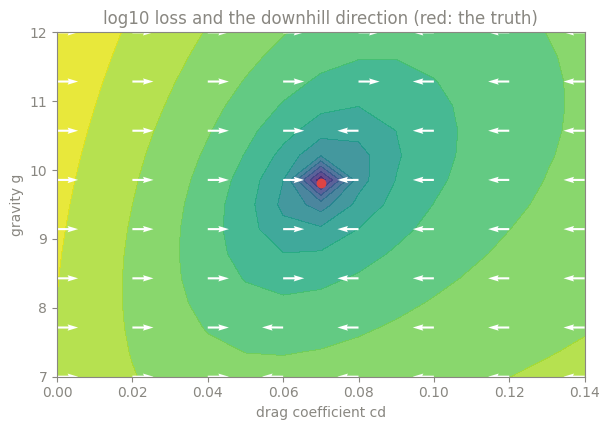

In [8]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.contourf(CD, GG, np.log10(value + 1e-12), levels=14, cmap="viridis", alpha=0.85)
span = np.array([0.14, 5.0])  # axis ranges, so arrows have equal length on the page
down = -np.stack([d_cd, d_g]) / span[:, None, None]
down = down / (np.linalg.norm(down, axis=0) + 1e-12) * 0.04
every = (slice(None, None, 2), slice(None, None, 2))
ax.quiver(CD[every], GG[every], down[0][every] * span[0], down[1][every] * span[1],
          angles="xy", scale_units="xy", scale=1, color="white", width=0.004)
ax.plot(0.07, 9.81, "o", color="#d44")
ax.set(xlabel="drag coefficient cd", ylabel="gravity g", title="log10 loss and the downhill direction (red: the truth)")
plt.tight_layout()

## What just happened

- Planes and Params both batch as one launch: the table above reads it off the program.
- `jacfwd` and `jacrev` use the forward and reverse kernels hawk derived; `hessian` uses both.
- A stepping kernel with a stop mask, and one built with `Guard(active_set=True)`, differentiate in forward mode too.
- You never wrote a derivative.

## Next

- [A stepping loop in `lax.scan`](14_jax_simulation_loop): balls that land and stop.
- [eagle inside your JAX program](../../interop/jax): what crosses, what is refused, the limits.